<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

****************************************************************************************************


<IPython.core.display.Math object>

... (104 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

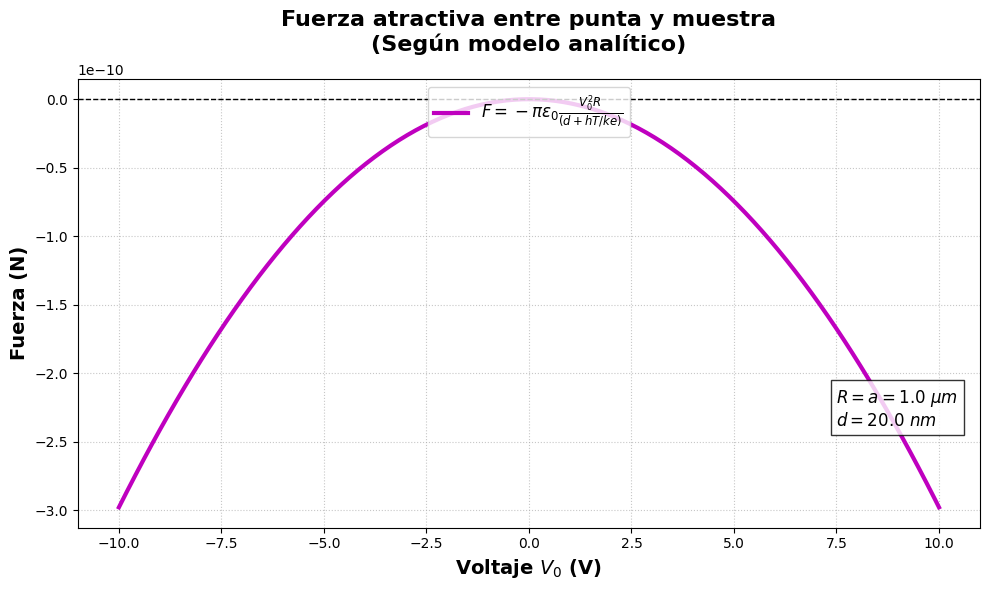

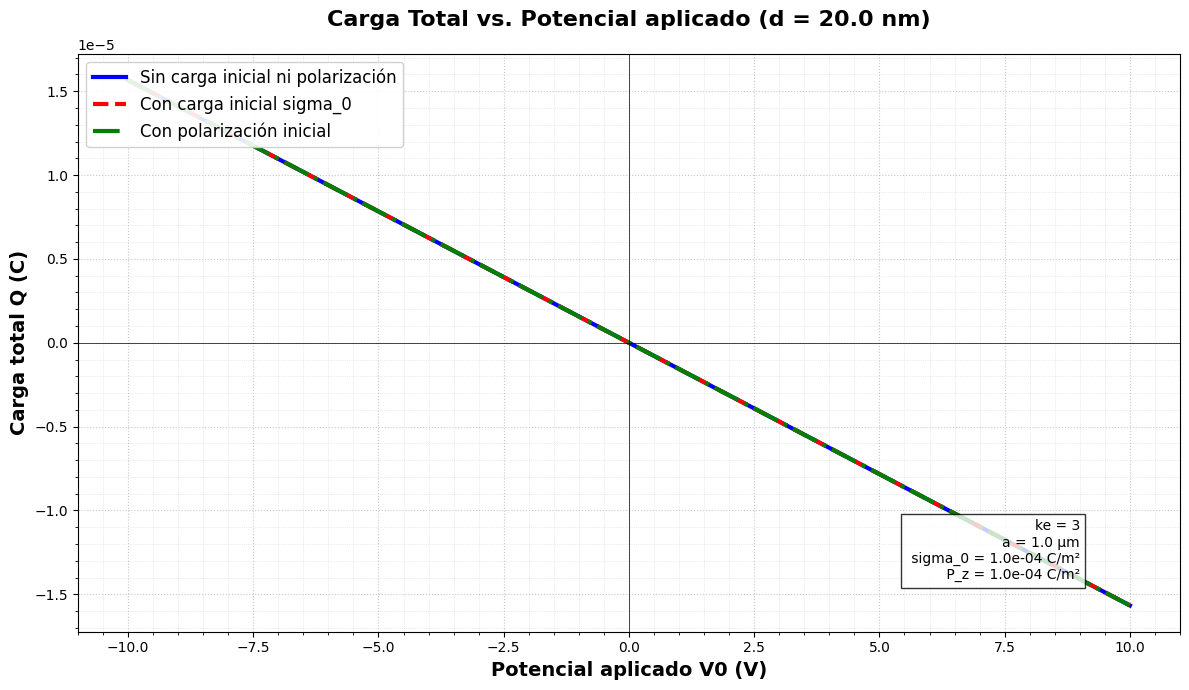

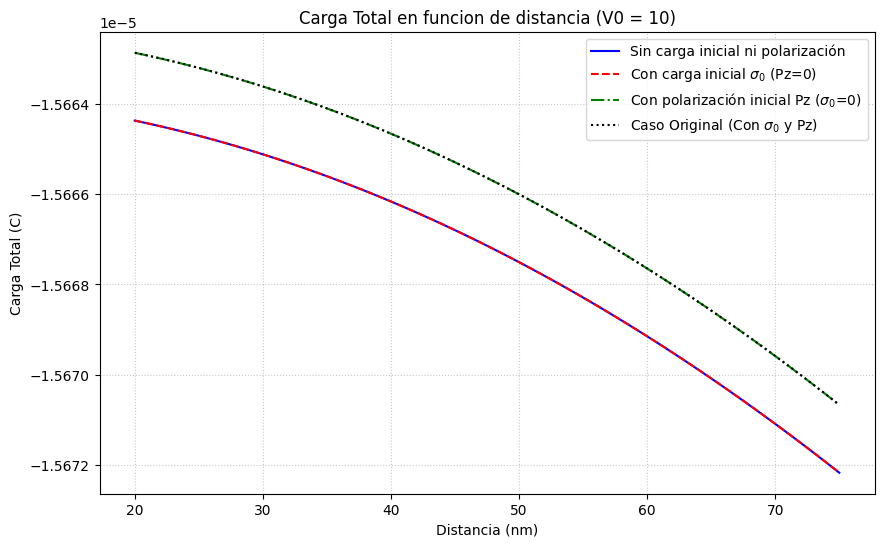

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import eval_legendre  
from IPython.display import Math, display, Latex

#Constante epsilon_0
eps0 = 8.854e-12

# Parámetros dentro de un diccionario
params = {
    'hT': 0.5e-6,      # Altura (m)
    'R': 20e-9,         # Radio (m)
    'alpha': np.pi/9,        # Ángulo (grados)
    'ke': 3,            # Constante dieléctrica
    'a': 1e-6,          # Radio de la esfera (m)
    'd0': 20e-9,        # Distancia inicial (m)
    'V0': 10,           # Voltaje (V)
    'sigma0': 100e-6,        # Densidad de carga inicial (C/m²) #(Primero veré el caso sin cargas iniciales, me quito la real)
    'Pz': 100e-6,            # Polarización inicial (C/m²) #(Y la real inicial)
    'Na': 30,           # Número de términos en a
    'Ntheta': 30,       # Número de puntos en theta
    'Ns': 30            # Número de términos en la sumatoria
}


#Funcion Para imprimir en latex:
def dpm(expr):
    return display(Math(expr))


# Función In(n) corregida
def In(n):
    return 1/(2*n + 1) * (eval_legendre(n - 1, 0) - eval_legendre(n + 1, 0))

# Funciones de potencial y gradiente
def potential(r, theta, n, ke, a):
    return (2*n + 1)/(ke*n + n + 1) * (r/a)**n *(1/a)*eval_legendre(n, np.sin(theta)) * In(n)
    #return (2*n + 1)/(ke*n + n + 1) * (r/a)**n *(1/a)*eval_legendre(n, np.sin(theta)) * In(n)

def field(r, theta, n, ke, a):
    return -(n)/r*potential(r, theta, n, ke, a)

#Dobles sumatorias
def double_summationPot(r, ke, a, Ns, Ntheta):
    total = 0.0
    theta_values = np.linspace(params['alpha'],np.pi/2 , Ntheta)

    for n in range(1, Ns + 1):
        for theta in theta_values:
            total += potential(r, theta, n, ke, a)
    return total

def double_summationField(r, ke, a, Ns, Ntheta):
    total = 0.0
    theta_values = np.linspace(params['alpha'],np.pi/2 , Ntheta)
    for n in range(1, Ns + 1):
        for theta in theta_values:
            total += field(r, theta, n, ke, a)
    return total

#Finalmente, calculo de la carga total utilizando las formulas del articulo
def carga_total_inducida(r,ke, a, Ns, Ntheta,sigma0,pz,V0):
    theta_vals = np.linspace(params['alpha'], np.pi / 2, Ntheta)
    Qtot = 0.0
    Er_theta = 0.0
    pol_theta = 0.0
    for theta in theta_vals:
        for n in range(1, Ns + 1):
            Er_theta += field(r, theta, n, ke, a)
            pol_theta += pz*np.sin(theta)
            dA = 2 * np.pi * a**2 #Parametrizacion de la figura
            Qtot += (V0*(ke-1)*eps0*Er_theta + sigma0 + pol_theta)* dA #No se especifica donde se implementa V0, entonces se le multiplica por el campo conocido
    return Qtot

def difCalc(x,y):
    return np.sqrt(((x-y)/x*100)**2)

# Cálculo principal
r_val = params['d0'] #Para medir el primer valor de la grafica, pero no cambia la naturaleza de la convergencia
phiIn = 100 #Escojo un potencial inicial que me de un alto error siempre
phiTot = double_summationPot(r_val, params['ke'], params['a'], params['Ns'], params['Ntheta'])
contador = 0
phiDif = difCalc(phiIn,phiTot)

#Ahora para el campo electrico
EIn = 100 #Escojo un campo inicial que me de un alto error siempre
ETot = double_summationField(r_val, params['ke'], params['a'], params['Ns'], params['Ntheta'])
EDif = difCalc(EIn,ETot)


# Mostrar resultado
#Primero potencial
dpm(rf"""
\text{{Resultado del POTENCIAL, con Ns=Ntheta=NA={30+contador}: }} \\
\phi(r=d0) = {phiTot:.4e} V
""")

dpm(rf"""
\text{{Luego, el porcentaje de diferencia fue {phiDif} \%}}
""")

#Luego campo electrico
dpm(rf"""
\text{{Resultado del CAMPO ELECTRICO, con Ns=Ntheta=NA={30+contador}: }} \\
E(r=d0) = {ETot:.4e} V/m
""")

dpm(rf"""
\text{{Luego, el porcentaje de diferencia fue {EDif} \%}}
""")
#**************************************************************************************
#Se arma el ciclo con condicion de convergencia
while phiDif > 2:
    phiIn = phiTot
    EIn=ETot
    params['Na'] += 1
    params['Ntheta'] += 1
    params['Ns'] += 1
    contador += 1

    print(f"{'*' * 100}")

    phiTot = double_summationPot(r_val, params['ke'], params['hT'], params['Ns'], params['Ntheta'])
    phiDif = difCalc(phiIn,phiTot)
    ETot = double_summationField(r_val, params['ke'], params['hT'], params['Ns'], params['Ntheta'])
    EDif = difCalc(EIn,ETot)
    # Mostrar resultado
    dpm(rf"""
    \text{{Resultado del POTENCIAL, con Ns=Ntheta=NA={30+contador}: }} \\
    \phi(r=d0) = {phiTot:.4e} V
    """)

    dpm(rf"""
    \text{{Luego, el porcentaje de diferencia fue {phiDif:.4f} \%}}
    """)

    #Luego campo electrico
    dpm(rf"""
    \text{{Resultado del CAMPO ELECTRICO, con Ns=Ntheta=NA={30+contador}: }} \\
    E(r=d0) = {ETot:.4e} V/m
    """)

    dpm(rf"""
    \text{{Luego, el porcentaje de diferencia fue {EDif:.4f} \%}}
    """)
#Ahora, calculamos la carga total en funcion de Vpunta
Qtot = carga_total_inducida(r_val,params['ke'], params['a'], 90, 90, params['sigma0'],params['Pz'],params['V0']) #Esto es la integral de sigmaT

#***********************************************************************************************************************************************
#IMPRESION DE GRAFICAS
# ========== GRAFICA 1 ==========
# Definición de la función de fuerza de la imagen (negativo)
def fuerza_imagen(V0, eps0, R, d):
    return -np.pi * eps0 * (V0**2) * R / (d+params['hT']/params['ke'])

# Rango de voltajes
V0_values = np.linspace(-10, 10, 200)
F_values = fuerza_imagen(V0_values, eps0, params['R'], params['d0'])

# Gráfica
plt.figure(figsize=(10,6))
plt.plot(V0_values, F_values, 'm-', linewidth=3, label=r'$F = -\pi \varepsilon_0 \frac{V_0^2 R}{(d+hT/ke)}$')

plt.xlabel('Voltaje $V_0$ (V)', fontsize=14, fontweight='bold')
plt.ylabel('Fuerza (N)', fontsize=14, fontweight='bold')
plt.title('Fuerza atractiva entre punta y muestra\n(Según modelo analítico)', fontsize=16, fontweight='bold', pad=20)

plt.text(7.5, min(F_values)*0.8,
          rf"$R = a = {params['a']*1e6:.1f} \ \mu m$" + '\n' +
          rf"$d = {params['d0']*1e9:.1f} \ nm$",
          fontsize=12,
          bbox=dict(facecolor='white', alpha=0.8))

plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.legend(fontsize=12, loc='upper center')

try:
    plt.tight_layout()
except:
    pass

plt.show()



# ========== GRAFICA 2 ==========
# Carga total en función del voltaje aplicado

# Definir el rango de V0 para esta gráfica
potenciales = np.linspace(-10, 10, 100) # De -10V a 10V con 100 puntos

# Guardar los parámetros originales antes de modificarlos para esta gráfica
original_sigma0_g2 = params['sigma0']
original_Pz_g2 = params['Pz']
original_V0_g2 = params['V0']

# Listas para almacenar las cargas calculadas
cargas_sin_nada_V = []
cargas_con_sigma_V = []
cargas_con_polarizacion_V = []

# Calcular cargas para el caso "Sin carga inicial ni polarización"
for V in potenciales:
    params['sigma0'] = 0
    params['Pz'] = 0
    params['V0'] = V # Usar el V actual del bucle
    Q = carga_total_inducida(params['d0'], params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    cargas_sin_nada_V.append(Q)

# Calcular cargas para el caso "Con carga inicial sigma_0 (Pz = 0)"
for V in potenciales:
    params['sigma0'] = original_sigma0_g2 # Usar el sigma0 original
    params['Pz'] = 0 # Pz es 0
    params['V0'] = V
    Q = carga_total_inducida(params['d0'], params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    cargas_con_sigma_V.append(Q)

# Calcular cargas para el caso "Con polarización inicial Pz (sigma0 = 0)"
for V in potenciales:
    params['sigma0'] = 0 # sigma0 es 0
    params['Pz'] = original_Pz_g2 # Usar el Pz original
    params['V0'] = V
    Q = carga_total_inducida(params['d0'], params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    cargas_con_polarizacion_V.append(Q)

# Restaurar los parámetros originales después de los cálculos para esta gráfica
params['sigma0'] = original_sigma0_g2
params['Pz'] = original_Pz_g2
params['V0'] = original_V0_g2


plt.figure(figsize=(12, 7))

plt.plot(potenciales, cargas_sin_nada_V, 'b-', linewidth=3,
         label='Sin carga inicial ni polarización')
plt.plot(potenciales, cargas_con_sigma_V, 'r--', linewidth=3,
         label=f'Con carga inicial sigma_0')
plt.plot(potenciales, cargas_con_polarizacion_V, 'g-.', linewidth=3,
         label=f'Con polarización inicial')

plt.xlabel('Potencial aplicado V0 (V)', fontsize=14, fontweight='bold')
plt.ylabel('Carga total Q (C)', fontsize=14, fontweight='bold')
plt.title(f'Carga Total vs. Potencial aplicado (d = {params["d0"]*1e9:.1f} nm)', fontsize=16, fontweight='bold', pad=20)

plt.text(9, min(cargas_sin_nada_V)*0.9,
          f'ke = {params["ke"]}\na = {params["a"]*1e6} μm\n sigma_0 = {original_sigma0_g2:.1e} C/m²\n P_z = {original_Pz_g2:.1e} C/m²', # Usar los valores originales aquí
          bbox=dict(facecolor='white', alpha=0.8),
          horizontalalignment='right')

plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='-', linewidth=0.5)
plt.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.legend(fontsize=12, loc='upper left', framealpha=0.9)

plt.minorticks_on()
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='gray', alpha=0.3)

try:
    plt.tight_layout()
except:
    pass

plt.show()

# ========== GRAFICA 3 ==========
# Carga total en función de la distancia punta-muestra

# Rangos de distancia
distances = np.linspace(20e-9, 75e-9, 100) # De 20nm a 75nm con 100 puntos

# Guardar los parámetros originales para esta sección también, para mayor seguridad
original_sigma0_g3 = params['sigma0']
original_Pz_g3 = params['Pz']
original_V0_g3 = params['V0'] # Asumiendo V0 es fijo para esta gráfica en params['V0']

# --- Caso 1: Sin carga inicial ni polarización ---
total_charges_no_initial = []
params['sigma0'] = 0
params['Pz'] = 0
# V0 se mantiene en su valor original definido en params, o el que haya quedado de los cálculos de convergencia
# Si V0 debe ser fijo para esta gráfica, asegúrate que params['V0'] tiene el valor deseado antes de este bloque
for d in distances:
    Q = carga_total_inducida(d, params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    total_charges_no_initial.append(Q)

# --- Caso 2: Con carga inicial sigma_0 (Pz = 0) ---
total_charges_with_sigma0 = []
params['sigma0'] = original_sigma0_g3 # Usar el sigma0 original
params['Pz'] = 0 # Pz a 0 para este caso
for d in distances:
    Q = carga_total_inducida(d, params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    total_charges_with_sigma0.append(Q)

# --- Caso 3: Con polarización inicial Pz (sigma0 = 0) ---
total_charges_with_Pz = []
params['sigma0'] = 0 # sigma0 a 0 para este caso
params['Pz'] = original_Pz_g3 # Usar el Pz original
for d in distances:
    Q = carga_total_inducida(d, params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    total_charges_with_Pz.append(Q)

# --- Caso 4: Caso Original (Con sigma0 y Pz) ---
total_charges_original = []
params['sigma0'] = original_sigma0_g3
params['Pz'] = original_Pz_g3
for d in distances:
    Q = carga_total_inducida(d, params['ke'], params['a'], params['Ns'], params['Ntheta'], params['sigma0'], params['Pz'], params['V0'])
    total_charges_original.append(Q)

# Restaurar los parámetros originales después de todos los cálculos para esta gráfica
params['sigma0'] = original_sigma0_g3
params['Pz'] = original_Pz_g3
params['V0'] = original_V0_g3


plt.figure(figsize=(10, 6))
plt.plot(distances * 1e9, total_charges_no_initial, 'b-', label='Sin carga inicial ni polarización')
plt.plot(distances * 1e9, total_charges_with_sigma0, 'r--', label='Con carga inicial $\\sigma_0$ (Pz=0)')
plt.plot(distances * 1e9, total_charges_with_Pz, 'g-.', label='Con polarización inicial Pz ($\\sigma_0$=0)')
plt.plot(distances * 1e9, total_charges_original, 'k:', label='Caso Original (Con $\\sigma_0$ y Pz)') # Añadiendo el caso original para completar

plt.xlabel('Distancia (nm)')
plt.ylabel('Carga Total (C)')
plt.title('Carga Total en funcion de distancia (V0 = 10)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()